In [1]:
from pathlib import Path
import pandas as pd
import json

# Locate the repository root
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data/processed/training_handoff/development.csv").exists()),
    None
)

if ROOT is None:
    raise FileNotFoundError("Cannot locate the Posters repository.")

# Load development data
df = pd.read_csv(
    ROOT / "data/processed/training_handoff/development.csv"
)

# Load predefined feature groups
with open(ROOT / "data/processed/feature_sets_v1.json") as f:
    feature_sets = json.load(f)

# Select the 12 visual features
visual_features = feature_sets["visual_baseline"]

X = df[visual_features]
y = df["y_active_mid_count"]

print("X shape:", X.shape)
print("y shape:", y.shape)

display(df.head())


X shape: (51, 12)
y shape: (51,)


,poster_year,target_year,n_posters,red_ratio_mean,red_ratio_n_valid,red_ratio_missing_ratio,r_mean_mean,r_mean_n_valid,r_mean_missing_ratio,g_mean_mean,...,archive_tag_agriculture_n_valid,archive_tag_agriculture_missing_ratio,archive_tag_mao_mean,archive_tag_mao_n_valid,archive_tag_mao_missing_ratio,archive_tag_red_flag_mean,archive_tag_red_flag_n_valid,archive_tag_red_flag_missing_ratio,y_active_mid_count,split
0,1949,1950,10,0.230524,10,0.0,0.581460,10,0.0,0.425264,...,10,0.0,0.200000,10,0.0,0.200000,10,0.0,6,development
1,1950,1951,26,0.063322,26,0.0,0.719032,26,0.0,0.669839,...,26,0.0,0.192308,26,0.0,0.153846,26,0.0,3,development
2,1951,1952,60,0.074302,60,0.0,0.667969,60,0.0,0.591164,...,60,0.0,0.083333,60,0.0,0.083333,60,0.0,3,development
3,1952,1953,98,0.048475,98,0.0,0.675367,98,0.0,0.610160,...,98,0.0,0.040816,98,0.0,0.051020,98,0.0,5,development
4,1953,1954,116,0.055321,116,0.0,0.634614,116,0.0,0.557587,...,116,0.0,0.051724,116,0.0,0.034483,116,0.0,6,development


count    51.000000
mean      3.352941
std       2.170931
min       0.000000
25%       2.000000
50%       3.000000
75%       5.000000
max      10.000000
Name: y_active_mid_count, dtype: float64


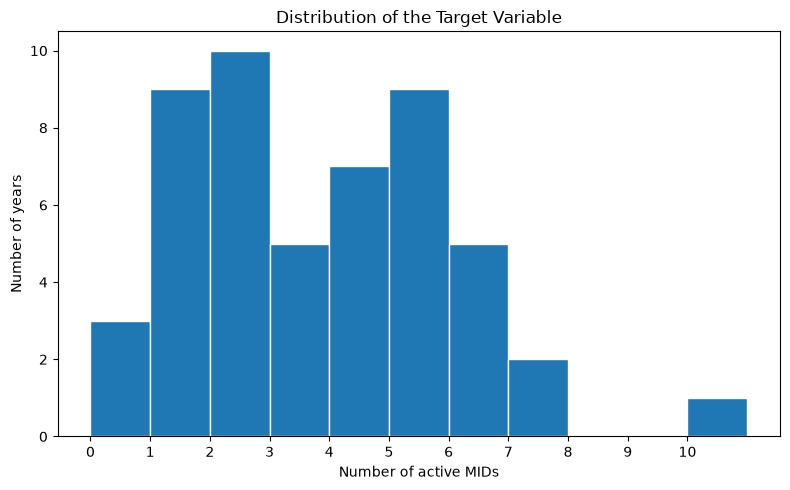

In [2]:
import matplotlib.pyplot as plt

print(y.describe())

plt.figure(figsize=(8, 5))
plt.hist(y, bins=range(12), edgecolor="white")

plt.xlabel("Number of active MIDs")
plt.ylabel("Number of years")
plt.title("Distribution of the Target Variable")
plt.xticks(range(11))
plt.tight_layout()
plt.show()


In [3]:
# Summary statistics for the 12 visual features
display(X.describe().T)

# Check missing values
print("Missing values:")
display(X.isna().sum())

# Check data types
print("Data types:")
display(X.dtypes)

,count,mean,std,min,25%,50%,75%,max
red_ratio_mean,51.0,0.114687,0.051677,0.048475,0.080405,0.100032,0.140486,0.282872
r_mean_mean,51.0,0.665075,0.033767,0.581460,0.647659,0.659412,0.680743,0.788598
g_mean_mean,51.0,0.579863,0.049072,0.425264,0.548972,0.581591,0.603518,0.744285
b_mean_mean,51.0,0.515753,0.062088,0.336440,0.474749,0.511794,0.546185,0.726500
saturation_mean_mean,51.0,0.305027,0.048853,0.154379,0.280440,0.298265,0.327040,0.437727
lightness_mean_mean,51.0,62.374555,4.142681,49.589322,59.767185,62.178627,64.490293,77.018163
lightness_std_mean,51.0,24.503068,1.671583,19.546000,23.446912,24.691355,25.600615,27.408779
lightness_p90_p10_mean,51.0,64.665982,4.554426,50.709250,60.964452,65.648069,68.105406,73.366994
size_short_cm_mean,51.0,51.498721,5.323919,30.711538,49.294955,52.636364,54.259384,61.915094
size_long_cm_mean,51.0,76.123111,8.278436,42.326923,72.707190,77.558333,79.978628,93.250000


Missing values:


red_ratio_mean            0
r_mean_mean               0
g_mean_mean               0
b_mean_mean               0
saturation_mean_mean      0
lightness_mean_mean       0
lightness_std_mean        0
lightness_p90_p10_mean    0
size_short_cm_mean        0
size_long_cm_mean         0
size_area_cm2_mean        0
size_aspect_ratio_mean    0
dtype: int64

Data types:


red_ratio_mean            float64
r_mean_mean               float64
g_mean_mean               float64
b_mean_mean               float64
saturation_mean_mean      float64
lightness_mean_mean       float64
lightness_std_mean        float64
lightness_p90_p10_mean    float64
size_short_cm_mean        float64
size_long_cm_mean         float64
size_area_cm2_mean        float64
size_aspect_ratio_mean    float64
dtype: object

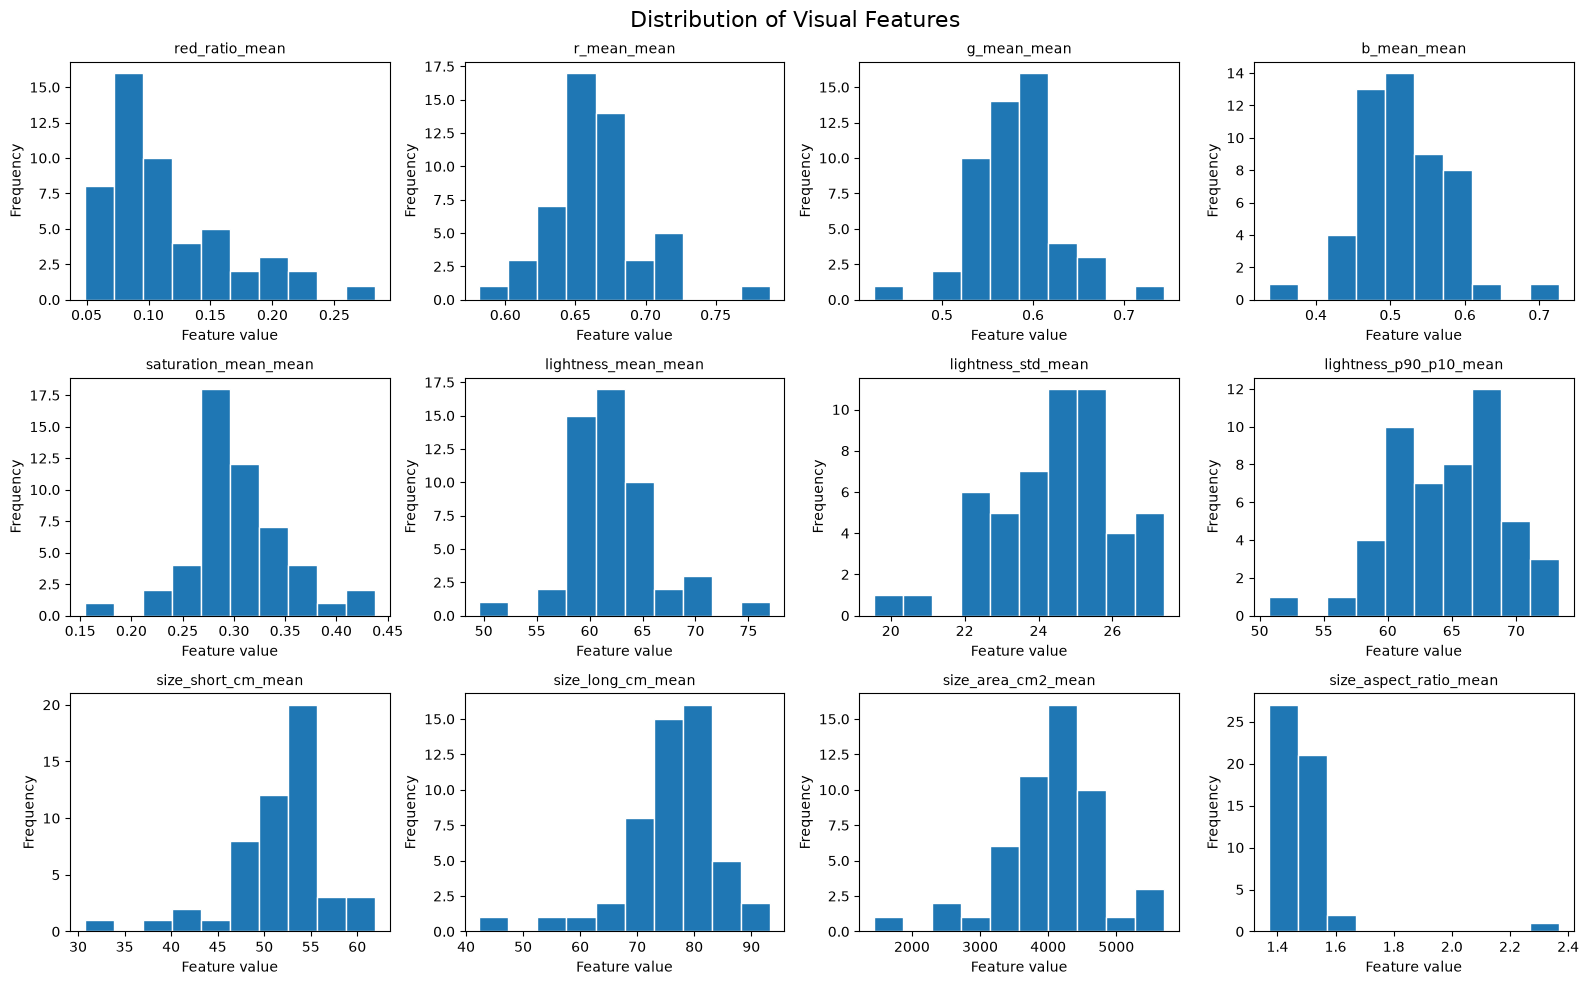

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for ax, feature in zip(axes.flat, visual_features):
    ax.hist(X[feature], bins=10, edgecolor="white")
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Frequency")

plt.suptitle("Distribution of Visual Features", fontsize=16)
plt.tight_layout()
plt.show()

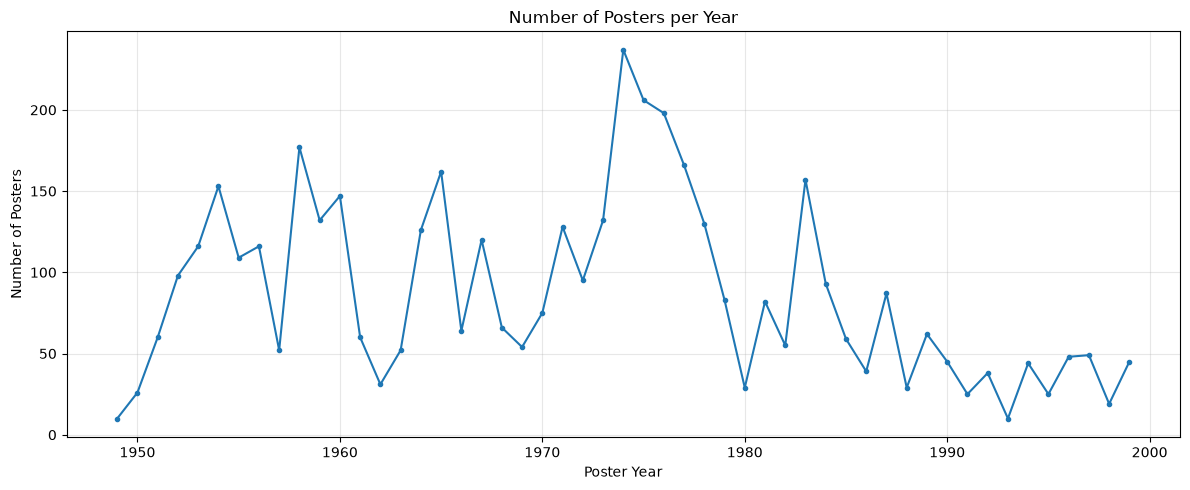

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["poster_year"],
    df["n_posters"],
    marker="o",
    markersize=3
)

plt.xlabel("Poster Year")
plt.ylabel("Number of Posters")
plt.title("Number of Posters per Year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

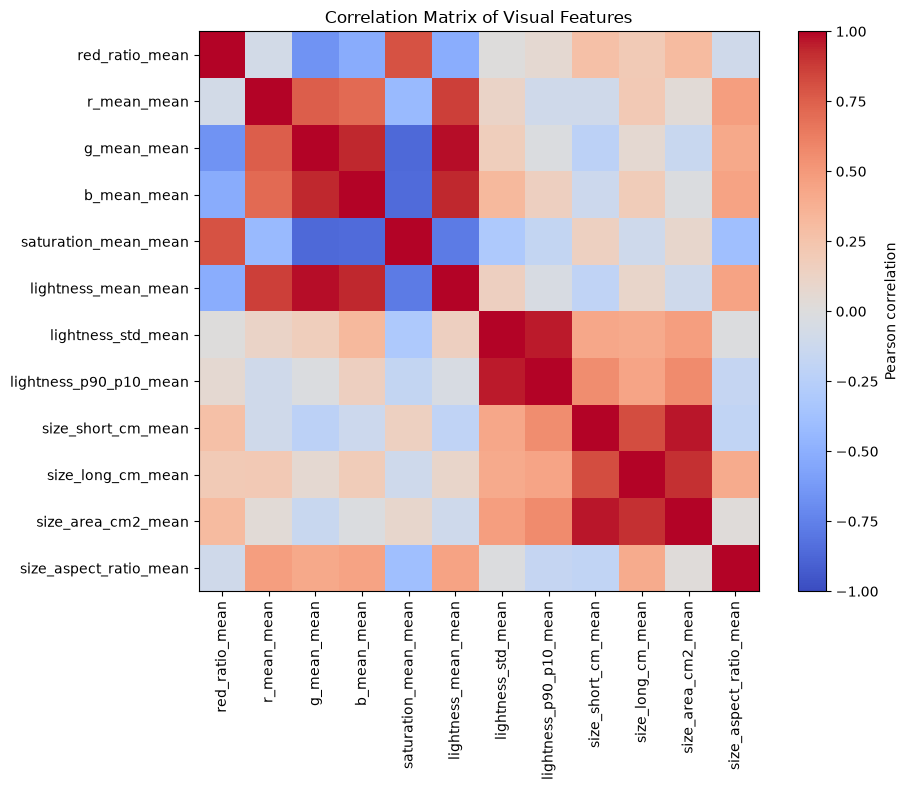

In [6]:
# Calculate Pearson correlations
corr = X.corr()

# Visualize the correlation matrix
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(visual_features)))
ax.set_yticks(range(len(visual_features)))

ax.set_xticklabels(visual_features, rotation=90)
ax.set_yticklabels(visual_features)

fig.colorbar(im, ax=ax, label="Pearson correlation")

ax.set_title("Correlation Matrix of Visual Features")

plt.tight_layout()
plt.show()

In [7]:
# Keep only the upper triangle, excluding the diagonal
import numpy as np

mask = np.triu(
    np.ones(corr.shape, dtype=bool), k=1
)

# Extract unique feature pairs
corr_pairs = corr.where(mask).stack()

# Sort by absolute correlation
corr_pairs = corr_pairs.sort_values(
    key=abs, ascending=False
)

display(corr_pairs.head(10))

g_mean_mean         lightness_mean_mean       0.981034
size_short_cm_mean  size_area_cm2_mean        0.961835
lightness_std_mean  lightness_p90_p10_mean    0.957538
g_mean_mean         b_mean_mean               0.934873
b_mean_mean         lightness_mean_mean       0.933231
size_long_cm_mean   size_area_cm2_mean        0.910296
r_mean_mean         lightness_mean_mean       0.860949
g_mean_mean         saturation_mean_mean     -0.860062
b_mean_mean         saturation_mean_mean     -0.852110
size_short_cm_mean  size_long_cm_mean         0.816430
dtype: float64

In [8]:
# Compute correlations between each feature and the target
target_corr = X.corrwith(y)

# Sort by absolute correlation
target_corr = target_corr.sort_values(
    key=abs, ascending=False
)

display(target_corr.to_frame(name="Correlation with target"))

,Correlation with target
b_mean_mean,-0.287117
lightness_std_mean,-0.243700
size_area_cm2_mean,-0.224651
lightness_p90_p10_mean,-0.222854
size_long_cm_mean,-0.206859
r_mean_mean,-0.198406
size_short_cm_mean,-0.197906
lightness_mean_mean,-0.197850
g_mean_mean,-0.168252
saturation_mean_mean,0.162162


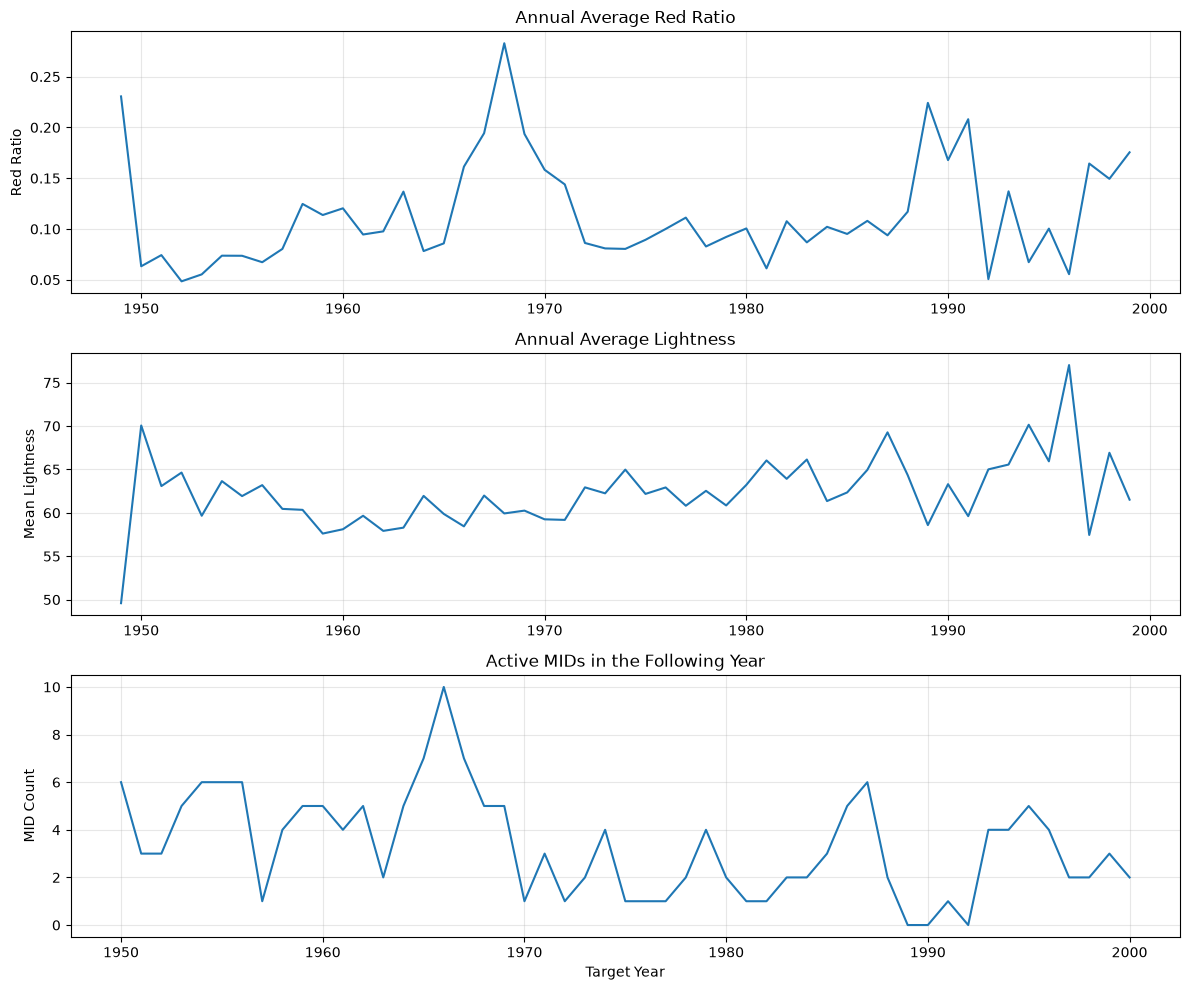

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(
    df["poster_year"],
    df["red_ratio_mean"]
)
axes[0].set_ylabel("Red Ratio")
axes[0].set_title("Annual Average Red Ratio")

axes[1].plot(
    df["poster_year"],
    df["lightness_mean_mean"]
)
axes[1].set_ylabel("Mean Lightness")
axes[1].set_title("Annual Average Lightness")

axes[2].plot(
    df["target_year"],
    y
)
axes[2].set_ylabel("MID Count")
axes[2].set_xlabel("Target Year")
axes[2].set_title("Active MIDs in the Following Year")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
# Autocorrelation at different lags
for lag in range(1, 6):
    r = df["y_active_mid_count"].autocorr(lag=lag)
    print(f"Lag {lag}: {r:.3f}")

Lag 1: 0.577
Lag 2: 0.299
Lag 3: 0.082
Lag 4: 0.001
Lag 5: 0.083


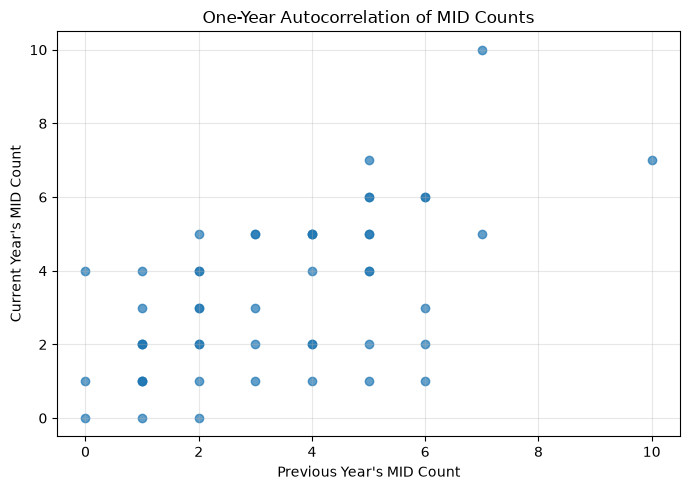

In [11]:
# Create a temporary lagged target for EDA
previous_y = df["y_active_mid_count"].shift(1)

plt.figure(figsize=(7, 5))

plt.scatter(
    previous_y,
    df["y_active_mid_count"],
    alpha=0.7
)

plt.xlabel("Previous Year's MID Count")
plt.ylabel("Current Year's MID Count")
plt.title("One-Year Autocorrelation of MID Counts")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Feature Selection

In [12]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the existing predefined feature sets
with open(ROOT / "data/processed/feature_sets_v1.json") as f:
    feature_sets = json.load(f)

# Our original 23-feature group
base_features = feature_sets["visual_plus_metadata_rules"]

# Two additional archive military indicators
archive_features = [
    "archive_theme_military_mean",
    "archive_tag_military_personnel_mean"
]

# Combine into one candidate feature set
candidate_features = base_features + archive_features

# Select the candidate predictors
X_candidates = df[candidate_features].copy()

print("Number of features:", len(candidate_features))
print("Shape:", X_candidates.shape)
print("Total missing values:", X_candidates.isna().sum().sum())

display(X_candidates[archive_features].describe().T)

Number of features: 25
Shape: (51, 25)
Total missing values: 0


,count,mean,std,min,25%,50%,75%,max
archive_theme_military_mean,51.0,0.062333,0.050823,0.0,0.023268,0.047619,0.093542,0.2
archive_tag_military_personnel_mean,51.0,0.142585,0.084208,0.0,0.093531,0.125000,0.183333,0.5


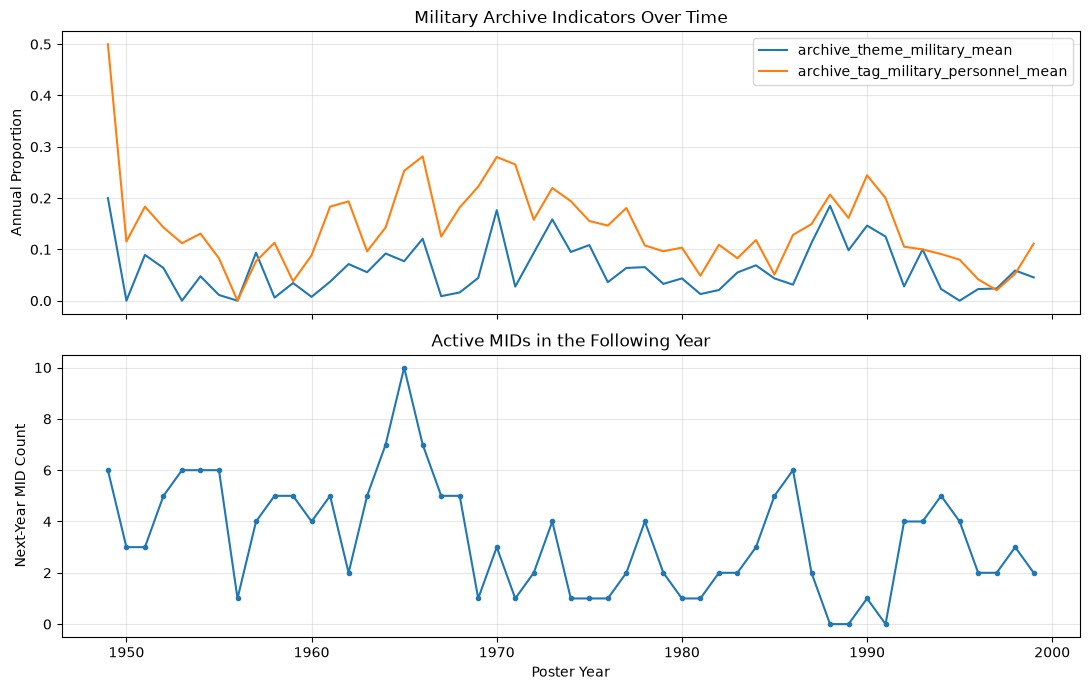

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Archive features
for feature in archive_features:
    axes[0].plot(
        df["poster_year"],
        df[feature],
        label=feature
    )

axes[0].set_ylabel("Annual Proportion")
axes[0].set_title("Military Archive Indicators Over Time")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Next-year dispute count
axes[1].plot(
    df["poster_year"],
    df["y_active_mid_count"],
    marker="o",
    markersize=3
)

axes[1].set_xlabel("Poster Year")
axes[1].set_ylabel("Next-Year MID Count")
axes[1].set_title("Active MIDs in the Following Year")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


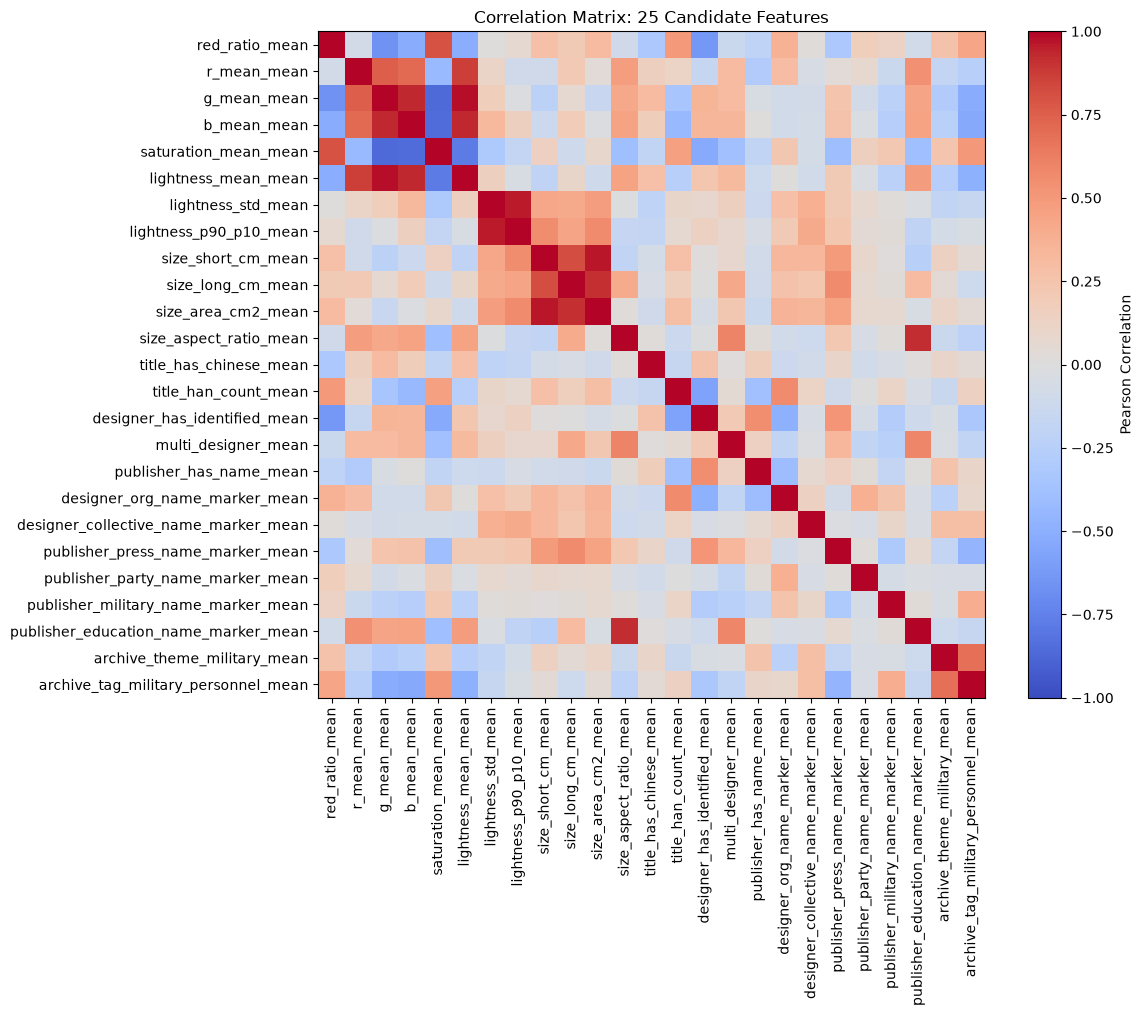

In [14]:
corr = X_candidates.corr()

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(candidate_features)))
ax.set_yticks(range(len(candidate_features)))

ax.set_xticklabels(candidate_features, rotation=90)
ax.set_yticklabels(candidate_features)

fig.colorbar(im, ax=ax, label="Pearson Correlation")

ax.set_title("Correlation Matrix: 25 Candidate Features")

plt.tight_layout()
plt.show()

In [15]:
# Select only the upper triangle, excluding the diagonal
mask = np.triu(
    np.ones(corr.shape, dtype=bool),
    k=1
)

# Extract unique correlations
corr_pairs = corr.where(mask).stack()

# Sort by absolute correlation
corr_pairs = corr_pairs.sort_values(
    key=abs,
    ascending=False
)

# Display feature pairs with |r| >= 0.9
strong_pairs = corr_pairs[corr_pairs.abs() >= 0.9]

display(strong_pairs.to_frame("Correlation"))

,,Correlation
g_mean_mean,lightness_mean_mean,0.981034
size_short_cm_mean,size_area_cm2_mean,0.961835
lightness_std_mean,lightness_p90_p10_mean,0.957538
g_mean_mean,b_mean_mean,0.934873
b_mean_mean,lightness_mean_mean,0.933231
size_aspect_ratio_mean,publisher_education_name_marker_mean,0.920427
size_long_cm_mean,size_area_cm2_mean,0.910296


In [16]:
# Count how many annual observations equal zero
zero_counts = (X_candidates == 0).sum()

# Calculate the proportion of zeros
zero_fraction = zero_counts / len(X_candidates)

# Count unique values
unique_counts = X_candidates.nunique()

sparsity_summary = pd.DataFrame({
    "zero_count": zero_counts,
    "zero_fraction": zero_fraction,
    "n_unique": unique_counts
})

display(
    sparsity_summary.sort_values(
        "zero_fraction", ascending=False
    )
)

,zero_count,zero_fraction,n_unique
publisher_party_name_marker_mean,50,0.980392,2
publisher_education_name_marker_mean,45,0.882353,7
designer_collective_name_marker_mean,40,0.784314,12
publisher_military_name_marker_mean,32,0.627451,19
designer_org_name_marker_mean,13,0.254902,38
archive_theme_military_mean,4,0.078431,45
multi_designer_mean,2,0.039216,49
archive_tag_military_personnel_mean,1,0.019608,49
publisher_press_name_marker_mean,1,0.019608,49
title_han_count_mean,0,0.000000,51


In [17]:
selected_features = [
    # Visual features
    "red_ratio_mean",
    "saturation_mean_mean",
    "lightness_mean_mean",
    "lightness_std_mean",
    "size_area_cm2_mean",
    "size_aspect_ratio_mean",

    # Basic metadata and name markers
    "title_han_count_mean",
    "designer_has_identified_mean",
    "designer_org_name_marker_mean",
    "publisher_military_name_marker_mean",

    # Retrospective archive features
    "archive_theme_military_mean",
    "archive_tag_military_personnel_mean"
]

X_selected = df[selected_features].copy()

print("Selected features:", len(selected_features))
print("Shape:", X_selected.shape)

Selected features: 12
Shape: (51, 12)


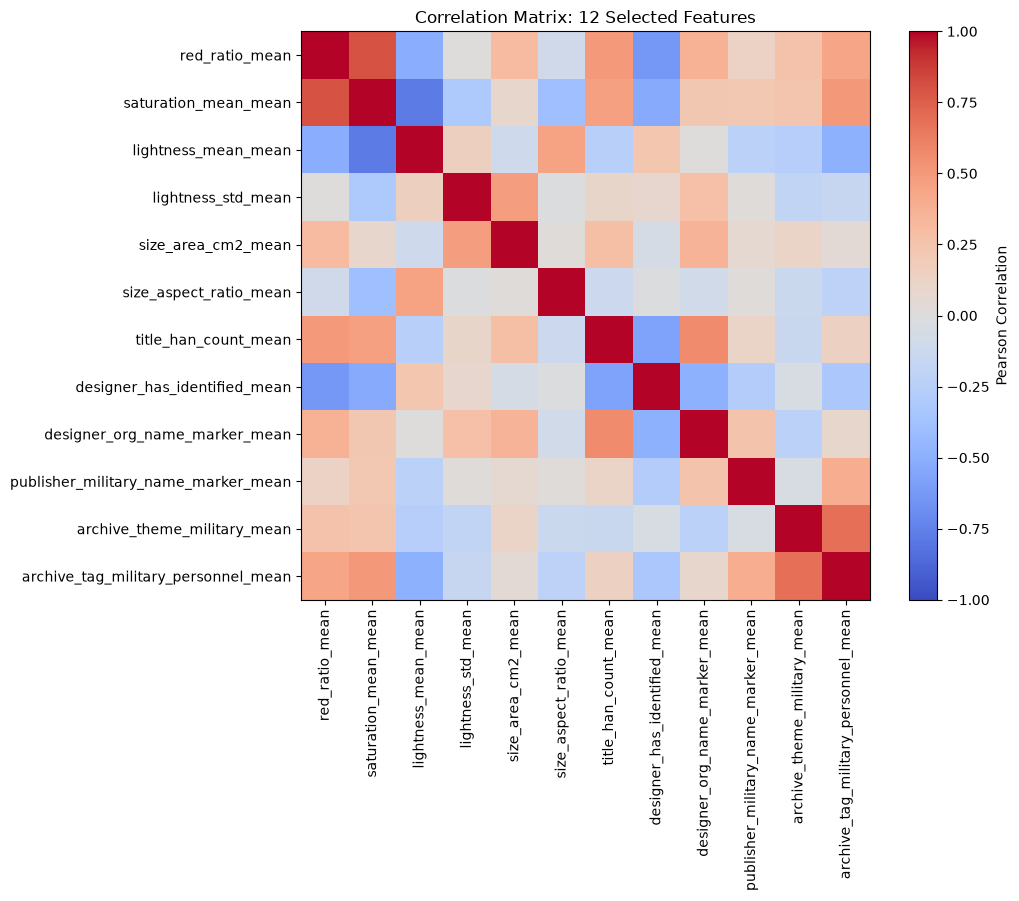

In [18]:
corr_selected = X_selected.corr()

fig, ax = plt.subplots(figsize=(11, 9))

im = ax.imshow(
    corr_selected,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(selected_features)))
ax.set_yticks(range(len(selected_features)))

ax.set_xticklabels(selected_features, rotation=90)
ax.set_yticklabels(selected_features)

fig.colorbar(im, ax=ax, label="Pearson Correlation")

ax.set_title("Correlation Matrix: 12 Selected Features")

plt.tight_layout()
plt.show()


## Feature Selection: Exploratory Summary

We initially considered 25 candidate predictors, comprising the 23 features in `visual_plus_metadata_rules` and two additional archive-derived military indicators.

Using the 51 annual observations in the development dataset (1949–1999), we examined feature distributions, sparsity, pairwise correlations, and interpretability.

### Selected Features

We proposed reducing the candidate set to 12 predictors:

**Visual Characteristics (6):**
- `red_ratio_mean`
- `saturation_mean_mean`
- `lightness_mean_mean`
- `lightness_std_mean`
- `size_area_cm2_mean`
- `size_aspect_ratio_mean`

**Basic Metadata and Rule-Based Indicators (4):**
- `title_han_count_mean`
- `designer_has_identified_mean`
- `designer_org_name_marker_mean`
- `publisher_military_name_marker_mean`

**Retrospective Archive Indicators (2):**
- `archive_theme_military_mean`
- `archive_tag_military_personnel_mean`

### Selection Rationale

The feature reduction primarily aimed to address multicollinearity, eliminate features with limited variation, and improve model interpretability.

- **Highly correlated features:** Removed redundant RGB, lightness, and physical-dimension measurements.
- **Sparse features:** Excluded several metadata indicators that were zero in most development years.
- **Interpretability:** Retained predictors representing distinct visual characteristics and relevant poster metadata.
- **Research relevance:** Included two military-related archive indicators to examine their potential association with subsequent militarized interstate disputes.

The maximum absolute pairwise Pearson correlation among retained predictors is approximately 0.801, compared with approximately 0.981 in the original candidate set.

### Limitations

This 12-feature subset is provisional rather than statistically optimal. The selected predictors will be compared against alternative feature sets using chronological cross-validation.

Because the shortlist was informed by exploratory analysis of the full development period, its cross-validation results should be interpreted as exploratory rather than fully unbiased estimates of the feature-selection procedure's performance.

Additionally, the archive theme and tag indicators were assigned retrospectively. Models including these variables will be treated as retrospective analyses rather than historically available real-time forecasting models.

### Next Steps

1. Train Ridge and regularized Poisson regression models.
2. Evaluate models using expanding-window chronological cross-validation.
3. Compare the selected feature set against the original visual-only baseline.
4. Assess predictive performance using MAE and RMSE.
5. Finalize model selection before evaluating the held-out test set.

## EDA Plots

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Locate the repository root
ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data/processed/training_handoff/development.csv").exists()
)

df = pd.read_csv(
    ROOT / "data/processed/training_handoff/development.csv"
)

df = df.sort_values("poster_year").reset_index(drop=True)

selected_features = [
    "red_ratio_mean",
    "saturation_mean_mean",
    "lightness_mean_mean",
    "lightness_std_mean",
    "size_area_cm2_mean",
    "size_aspect_ratio_mean",
    "title_han_count_mean",
    "designer_has_identified_mean",
    "designer_org_name_marker_mean",
    "publisher_military_name_marker_mean",
    "archive_theme_military_mean",
    "archive_tag_military_personnel_mean"
]

X = df[selected_features]
y = df["y_active_mid_count"]

# Save figures outside the GitHub repository
OUTPUT = Path.home() / "Downloads" / "Posters_EDA_Report_Figures"
OUTPUT.mkdir(parents=True, exist_ok=True)

def save_plot(fig, filename):
    fig.savefig(OUTPUT / f"{filename}.png",
                dpi=300, bbox_inches="tight")
    fig.savefig(OUTPUT / f"{filename}.svg",
                bbox_inches="tight")

print(df.shape)

(51, 125)


### Figure 1: Target variable: Time series and distribution (recommended)

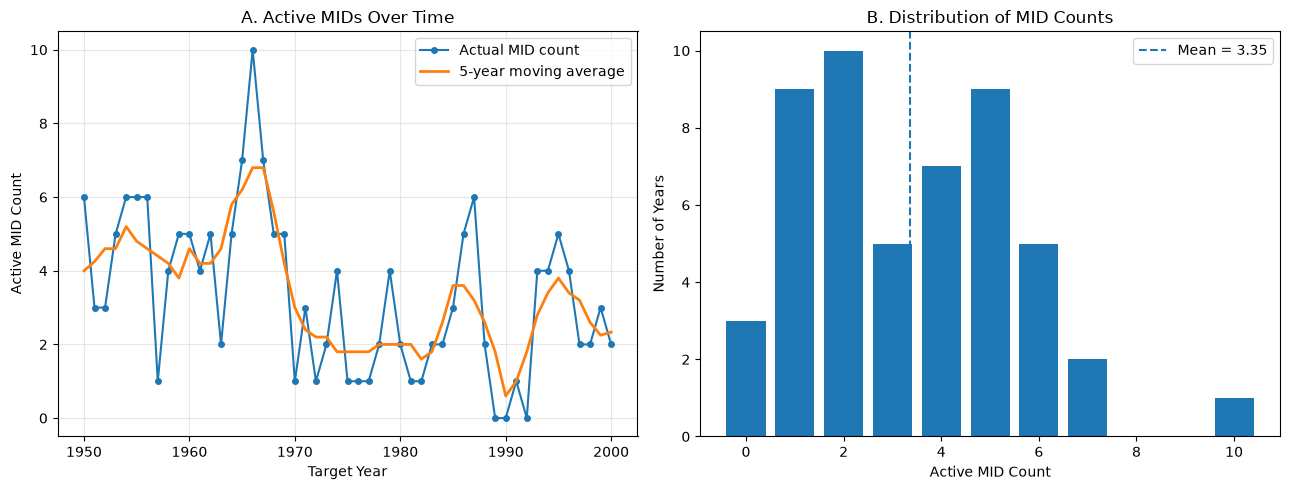

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel A: Time series
axes[0].plot(
    df["target_year"], y,
    marker="o", markersize=4,
    label="Actual MID count"
)

rolling_mean = y.rolling(
    window=5, center=True, min_periods=3
).mean()

axes[0].plot(
    df["target_year"], rolling_mean,
    linewidth=2, label="5-year moving average"
)

axes[0].set_title("A. Active MIDs Over Time")
axes[0].set_xlabel("Target Year")
axes[0].set_ylabel("Active MID Count")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Panel B: Target distribution
counts = y.value_counts().sort_index()

axes[1].bar(counts.index, counts.values)

axes[1].axvline(
    y.mean(), linestyle="--",
    label=f"Mean = {y.mean():.2f}"
)

axes[1].set_title("B. Distribution of MID Counts")
axes[1].set_xlabel("Active MID Count")
axes[1].set_ylabel("Number of Years")
axes[1].legend()

plt.tight_layout()
save_plot(fig, "01_target_overview")
plt.show()

### Figure 2: Visual features over time

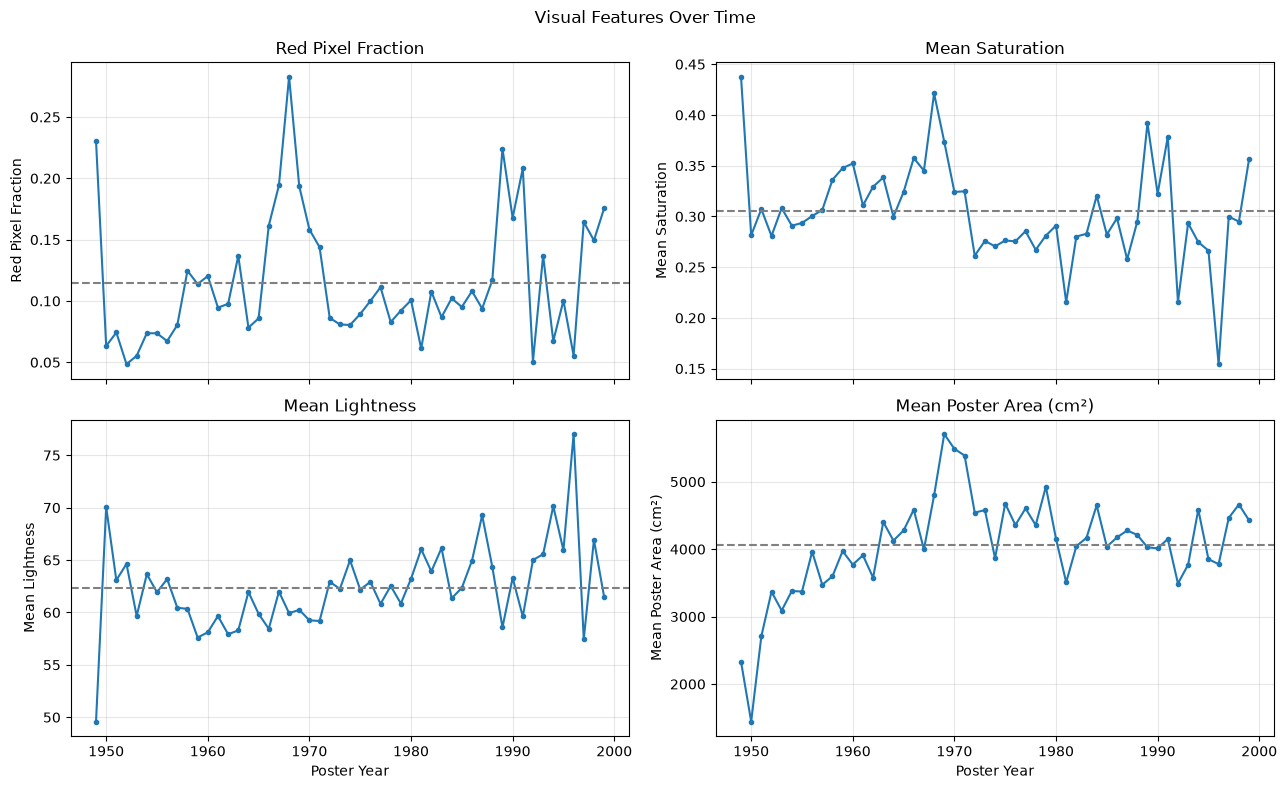

In [21]:
features_to_plot = {
    "red_ratio_mean": "Red Pixel Fraction",
    "saturation_mean_mean": "Mean Saturation",
    "lightness_mean_mean": "Mean Lightness",
    "size_area_cm2_mean": "Mean Poster Area (cm²)"
}

fig, axes = plt.subplots(
    2, 2, figsize=(13, 8), sharex=True
)

for ax, (feature, label) in zip(
    axes.flat, features_to_plot.items()
):
    ax.plot(
        df["poster_year"],
        df[feature],
        marker="o",
        markersize=3
    )

    ax.axhline(
        df[feature].mean(),
        linestyle="--",
        color="gray",
        label="Period mean"
    )

    ax.set_title(label)
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)

for ax in axes[-1]:
    ax.set_xlabel("Poster Year")

plt.suptitle("Visual Features Over Time")
plt.tight_layout()
save_plot(fig, "02_visual_feature_trends")
plt.show()

### Figure 3: Military archive indicators and next-year disputes (recommended)

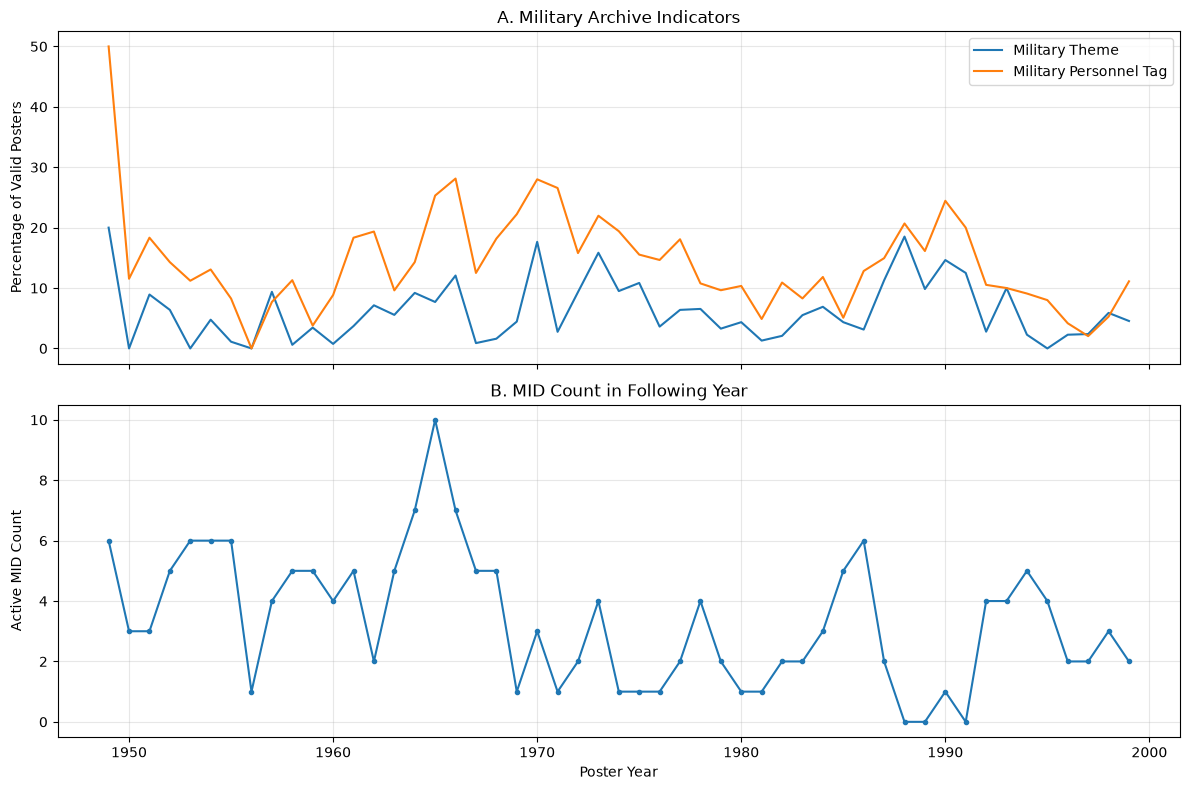

In [22]:
fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

# Panel A: Military archive indicators
axes[0].plot(
    df["poster_year"],
    df["archive_theme_military_mean"] * 100,
    label="Military Theme"
)

axes[0].plot(
    df["poster_year"],
    df["archive_tag_military_personnel_mean"] * 100,
    label="Military Personnel Tag"
)

axes[0].set_title("A. Military Archive Indicators")
axes[0].set_ylabel("Percentage of Valid Posters")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Panel B: Following-year MID count
axes[1].plot(
    df["poster_year"],
    y,
    marker="o",
    markersize=3
)

axes[1].set_title("B. MID Count in Following Year")
axes[1].set_xlabel("Poster Year")
axes[1].set_ylabel("Active MID Count")
axes[1].grid(alpha=0.3)

plt.tight_layout()
save_plot(fig, "03_archive_military_and_target")
plt.show()

### Figure 4: Correlation heatmap of the selected features (recommended)

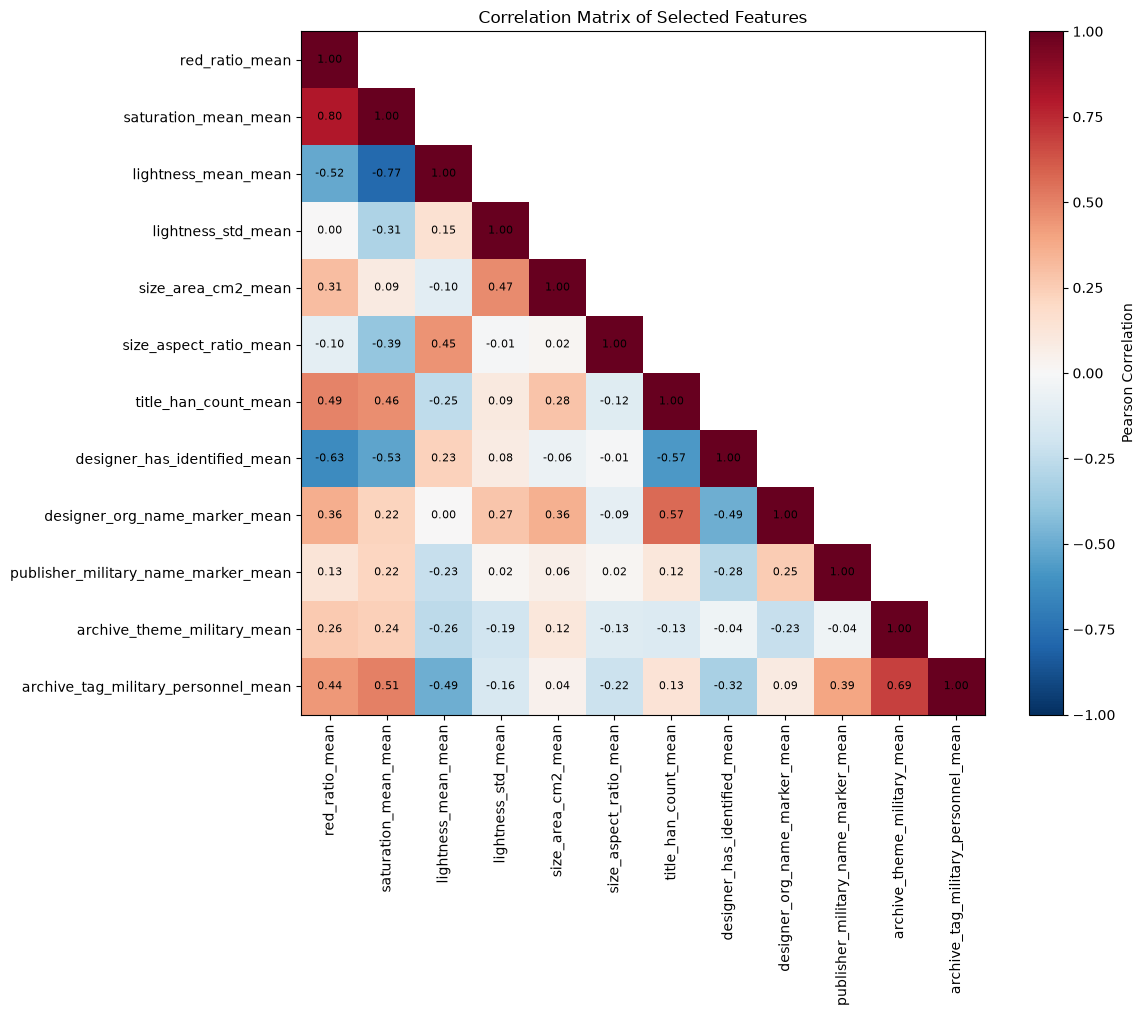

In [23]:
corr = X.corr()

# Mask the upper triangle to avoid duplication
mask = np.triu(
    np.ones(corr.shape, dtype=bool), k=1
)

masked_corr = np.ma.masked_where(
    mask, corr.to_numpy()
)

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    masked_corr,
    cmap="RdBu_r",
    vmin=-1, vmax=1
)

ax.set_xticks(range(len(selected_features)))
ax.set_yticks(range(len(selected_features)))

ax.set_xticklabels(
    selected_features, rotation=90
)
ax.set_yticklabels(selected_features)

# Display correlation coefficients
for i in range(len(selected_features)):
    for j in range(i + 1):
        value = corr.iloc[i, j]

        ax.text(
            j, i, f"{value:.2f}",
            ha="center", va="center",
            fontsize=8
        )

fig.colorbar(im, ax=ax, label="Pearson Correlation")
ax.set_title("Correlation Matrix of Selected Features")

plt.tight_layout()
save_plot(fig, "04_selected_feature_correlations")
plt.show()

### Figure 5: Feature-target correlations

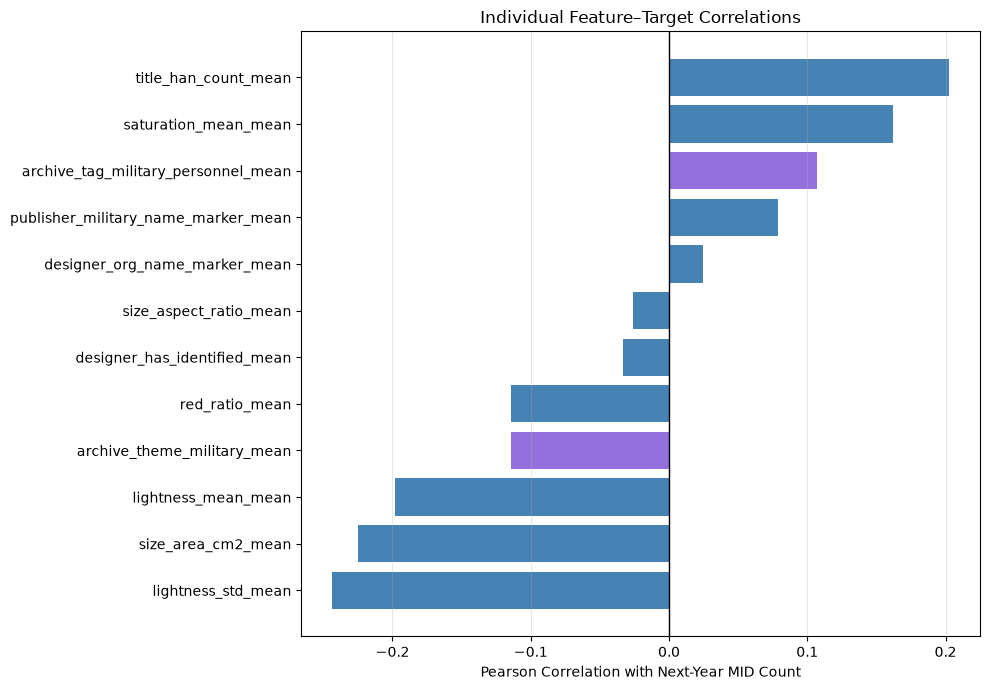

In [24]:
# Correlation between each feature and y
target_corr = X.corrwith(y).sort_values()

fig, ax = plt.subplots(figsize=(10, 7))

# Distinguish archive-derived features
colors = [
    "mediumpurple" if feature.startswith("archive_")
    else "steelblue"
    for feature in target_corr.index
]

ax.barh(
    target_corr.index,
    target_corr.values,
    color=colors
)

ax.axvline(0, color="black", linewidth=1)

ax.set_xlabel("Pearson Correlation with Next-Year MID Count")
ax.set_title("Individual Feature–Target Correlations")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
save_plot(fig, "05_feature_target_correlations")
plt.show()

### Figure 6: Poster availability and archive coverage (recommended)

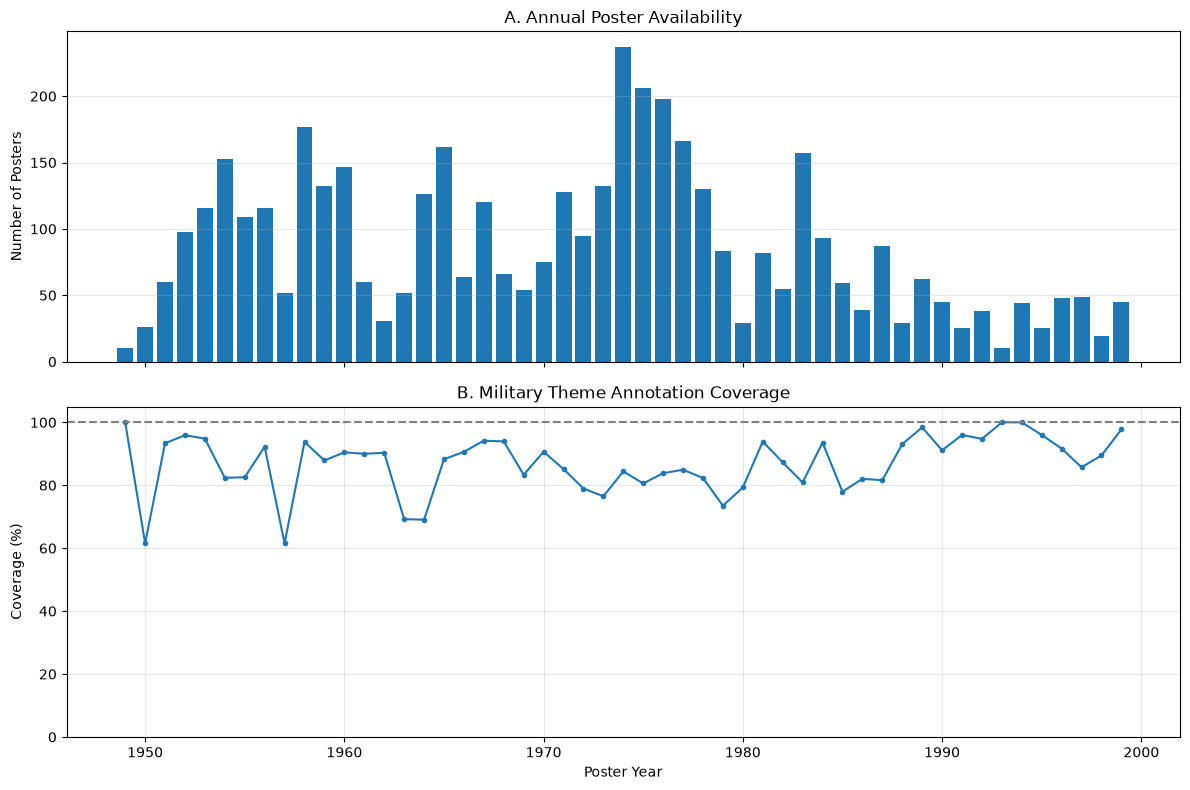

In [25]:
# Fraction of posters with a known military-theme label
theme_coverage = (
    df["archive_theme_military_n_valid"]
    / df["n_posters"]
) * 100

fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

# Panel A: Number of posters
axes[0].bar(
    df["poster_year"],
    df["n_posters"]
)

axes[0].set_title("A. Annual Poster Availability")
axes[0].set_ylabel("Number of Posters")
axes[0].grid(axis="y", alpha=0.3)

# Panel B: Annotation coverage
axes[1].plot(
    df["poster_year"],
    theme_coverage,
    marker="o",
    markersize=3
)

axes[1].axhline(
    100, linestyle="--",
    color="gray"
)

axes[1].set_title("B. Military Theme Annotation Coverage")
axes[1].set_xlabel("Poster Year")
axes[1].set_ylabel("Coverage (%)")
axes[1].set_ylim(0, 105)
axes[1].grid(alpha=0.3)

plt.tight_layout()
save_plot(fig, "06_poster_and_label_coverage")
plt.show()